In [20]:
import pandas as pd
import numpy as np

## Preprocesamiento de los datos

Antes de utilizar los datos en el modelo, se deben preprocesar, ya que es necesario vectorizar, normalizar valores y manejar valores que faltan.

### Unificar y limpiar datasets
En esta primera fase, se va a realizar la unión de los datasets de cada temporada, desde la 2010-2011 hasta la 2025-2026, en un único dataset para poder usar los datos de forma correcta y de forma sencilla. Además, añadimos un valor que identifique la temporada, para diferenciarlas bien.

In [21]:
pd.set_option("display.max_columns", None)

temporadas = {1:"2010-2011.csv", 2:"2011-2012.csv", 3:"2012-2013.csv", 4:"2013-2014.csv", 5:"2014-2015.csv", 6:"2015-2016.csv", 7:"2016-2017.csv",
         8:"2017-2018.csv", 9:"2018-2019.csv", 10:"2019-2020.csv", 11:"2020-2021.csv", 12:"2021-2022.csv", 13:"2022-2023.csv", 14:"2023-2024.csv",
          15:"2024-2025.csv", 16: "2025-2026.csv"}

grupo_temporadas = []

for temp, archivo in temporadas.items():
    aux = pd.read_csv(archivo, sep=',').copy()
    aux.insert(0, "Temporada", temp)
    grupo_temporadas.append(aux)
     # añadimos la columna nueva
laliga = pd.concat(grupo_temporadas, ignore_index=True)

laliga.info()
laliga.head()

<class 'pandas.DataFrame'>
RangeIndex: 6080 entries, 0 to 6079
Columns: 192 entries, Temporada to LBCA
dtypes: float64(168), int64(17), str(7)
memory usage: 8.9 MB


,Temporada,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,BWH,BWD,BWA,GBH,GBD,GBA,IWH,IWD,IWA,LBH,LBD,LBA,SBH,SBD,SBA,WHH,WHD,WHA,SJH,SJD,SJA,VCH,VCD,VCA,BSH,BSD,BSA,Bb1X2,BbMxH,BbAvH,BbMxD,BbAvD,BbMxA,BbAvA,BbOU,BbMx>2.5,BbAv>2.5,BbMx<2.5,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSH,PSD,PSA,PSCH,PSCD,PSCA,Time,MaxH,MaxD,MaxA,AvgH,AvgD,AvgA,B365>2.5,B365<2.5,P>2.5,P<2.5,Max>2.5,Max<2.5,Avg>2.5,Avg<2.5,AHh,B365AHH,B365AHA,PAHH,PAHA,MaxAHH,MaxAHA,AvgAHH,AvgAHA,B365CH,B365CD,B365CA,BWCH,BWCD,BWCA,IWCH,IWCD,IWCA,WHCH,WHCD,WHCA,VCCH,VCCD,VCCA,MaxCH,MaxCD,MaxCA,AvgCH,AvgCD,AvgCA,B365C>2.5,B365C<2.5,PC>2.5,PC<2.5,MaxC>2.5,MaxC<2.5,AvgC>2.5,AvgC<2.5,AHCh,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFH,BFD,BFA,1XBH,1XBD,1XBA,BFEH,BFED,BFEA,BFE>2.5,BFE<2.5,BFEAHH,BFEAHA,BFCH,BFCD,BFCA,1XBCH,1XBCD,1XBCA,BFECH,BFECD,BFECA,BFEC>2.5,BFEC<2.5,BFECAHH,BFECAHA,BFDH,BFDD,BFDA,BMGMH,BMGMD,BMGMA,BVH,BVD,BVA,CLH,CLD,CLA,BFDCH,BFDCD,BFDCA,BMGMCH,BMGMCD,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,1,SP1,28/08/10,Hercules,Ath Bilbao,0,1,A,0,0,D,9,14,3,5,15,18,10,1,2,4,1,0,2.50,3.25,2.8,2.55,3.20,2.65,2.60,3.25,2.6,2.6,3.1,2.5,2.5,3.2,2.5,2.50,3.20,2.6,2.50,3.20,2.60,2.6,3.20,2.75,2.50,3.12,2.75,2.50,3.25,2.6,32.0,2.75,2.56,3.34,3.22,2.88,2.72,23.0,2.26,2.12,1.73,1.67,25.0,0.0,1.92,1.84,2.10,1.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,SP1,28/08/10,Levante,Sevilla,1,4,A,1,2,A,7,14,4,8,20,22,4,2,4,4,0,0,3.60,3.50,2.0,3.90,3.30,1.91,3.60,3.30,2.0,3.1,3.3,2.1,3.2,3.2,2.0,3.50,3.20,2.0,3.40,3.30,2.00,3.6,3.25,2.10,3.75,3.30,1.95,3.25,3.30,2.1,32.0,3.98,3.59,3.58,3.35,2.10,2.03,27.0,2.05,1.95,1.92,1.82,15.0,0.0,2.75,2.54,1.53,1.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,SP1,28/08/10,Malaga,Valencia,1,3,A,1,1,D,19,21,5,8,16,15,7,10,2,5,0,0,2.88,3.30,2.4,2.85,3.30,2.35,2.85,3.25,2.4,2.7,3.2,2.4,2.8,3.2,2.2,2.65,3.25,2.4,2.90,3.25,2.25,2.8,3.25,2.50,2.88,3.20,2.40,2.90,3.25,2.3,32.0,3.19,2.91,3.39,3.26,2.50,2.38,28.0,2.14,2.04,1.80,1.74,19.0,0.0,2.25,2.08,1.83,1.71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,SP1,29/08/10,Espanol,Getafe,3,1,H,1,0,H,17,13,8,1,17,9,8,4,3,4,0,0,2.10,3.30,3.5,2.15,3.25,3.25,2.10,3.25,3.4,2.0,3.2,3.4,2.1,3.2,3.0,2.10,3.20,3.2,2.10,3.25,3.25,2.1,3.25,3.60,2.10,3.20,3.50,2.10,3.20,3.3,35.0,2.20,2.12,3.37,3.25,3.96,3.42,25.0,2.43,2.25,1.65,1.60,21.0,0.0,1.57,1.51,2.69,2.48,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

Una vez tenemos unidos todas las temporadas en un mismo dataset, vamos a eliminar las columnas que no vamos a utilizar en un principio, que son todas las columnas de cuotas de otras casas de apuestas que no sean *Bet365* o *Pinnacle*, para reducir el tamaño del dataset. Las estadísticas del partido, de momento, las mantenemos todas.

In [22]:
columns = ["Temporada", "Date", "HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR", "HTHG", "HTAG", "HTR", "HS", "AS", "HST", "AST", "HF", "AF", "HC", "AC", "HY", "AY","HR", "AR", "B365H", "B365D",
            "B365A", "PSH", "PSD", "PSA"]
laliga = laliga[columns]
laliga.info()
laliga.head()

<class 'pandas.DataFrame'>
RangeIndex: 6080 entries, 0 to 6079
Data columns (total 28 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Temporada  6080 non-null   int64  
 1   Date       6080 non-null   str    
 2   HomeTeam   6080 non-null   str    
 3   AwayTeam   6080 non-null   str    
 4   FTHG       6080 non-null   int64  
 5   FTAG       6080 non-null   int64  
 6   FTR        6080 non-null   str    
 7   HTHG       6080 non-null   int64  
 8   HTAG       6080 non-null   int64  
 9   HTR        6080 non-null   str    
 10  HS         6080 non-null   int64  
 11  AS         6080 non-null   int64  
 12  HST        6080 non-null   int64  
 13  AST        6080 non-null   int64  
 14  HF         6080 non-null   int64  
 15  AF         6080 non-null   int64  
 16  HC         6080 non-null   int64  
 17  AC         6080 non-null   int64  
 18  HY         6080 non-null   int64  
 19  AY         6080 non-null   int64  
 20  HR         6080 non

,Temporada,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,HS,AS,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR,B365H,B365D,B365A,PSH,PSD,PSA
0,1,28/08/10,Hercules,Ath Bilbao,0,1,A,0,0,D,9,14,3,5,15,18,10,1,2,4,1,0,2.50,3.25,2.8,NaN,NaN,NaN
1,1,28/08/10,Levante,Sevilla,1,4,A,1,2,A,7,14,4,8,20,22,4,2,4,4,0,0,3.60,3.50,2.0,NaN,NaN,NaN
2,1,28/08/10,Malaga,Valencia,1,3,A,1,1,D,19,21,5,8,16,15,7,10,2,5,0,0,2.88,3.30,2.4,NaN,NaN,NaN
3,1,29/08/10,Espanol,Getafe,3,1,H,1,0,H,17,13,8,1,17,9,8,4,3,4,0,0,2.10,3.30,3.5,NaN,NaN,NaN
4,1,29/08/10,La Coruna,Zaragoza,0,0,D,0,0,D,8,8,2,3,16,19,4,6,0,1,0,0,2.10,3.30,3.5,NaN,NaN,NaN


Las columnas que no interesaban inicialmente han sido eliminadas y ahora al mostrar la información del dataset, se puede ver que hay partidos que no tienen las cuotas de *Pinnacle*, ya que las columnas de *PSH*, *PSD* y *PSA* no tienen el mismo número de filas que el resto del dataset. Se va a proceder a encontrar cuál o cuáles son las temporadas que no contienen esta información


In [23]:
columns_pinnacle = ["PSH", "PSD", "PSA"]
nulos = laliga[columns_pinnacle].isna().groupby(laliga["Temporada"]).sum()
print(nulos)

           PSH  PSD  PSA
Temporada               
1          380  380  380
2          380  380  380
3            0    0    0
4            0    0    0
5            2    2    2
6            1    1    1
7            0    0    0
8            0    0    0
9            0    0    0
10           2    2    2
11           0    0    0
12           1    1    1
13           0    0    0
14           0    0    0
15           0    0    0
16         191  191  191


Al realizar esta exploración, se puede apreciar que las dos primeras temporadas y varios partidos entre las temporadas 2014-2015 y 2021-2022, pero como estos son los partidos de entrenamiento, aquí no hacen falta las cuotas, ya que estás son solo para comparar al final.  
Sin embargo, se puede ver que en la última temporada sí que falta la mitad de los partidos. 

In [24]:
temp16 = laliga[laliga["Temporada"] == 16].reset_index(drop=True)
nulos = temp16["PSH"].isna().to_numpy()
n = nulos.sum()

son_ultimas = n > 0 and nulos[-n:].all()   # los n últimos son todos nulos
print(f"{n} nulos de {len(temp16)} filas")
print("¿Son las últimas filas y sin huecos?", son_ultimas)

191 nulos de 380 filas
¿Son las últimas filas y sin huecos? True


Con esta exploración, se puede comprobar que los partidos que no tienen cuota son las últimas filas, es decir, que sigue un orden temporal, (aqui poner en el documento que el dueño del dataset no los ha incluido más a partir de la fecha en la que sea el último partido). Por lo tanto, los podemos eliminar del dataset sin afectar al resultado final.

In [25]:
mascara = (laliga["Temporada"] == 16) & laliga["PSH"].isna()
print(mascara.sum())   
laliga = laliga[~mascara].reset_index(drop=True)
laliga.info()

191
<class 'pandas.DataFrame'>
RangeIndex: 5889 entries, 0 to 5888
Data columns (total 28 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Temporada  5889 non-null   int64  
 1   Date       5889 non-null   str    
 2   HomeTeam   5889 non-null   str    
 3   AwayTeam   5889 non-null   str    
 4   FTHG       5889 non-null   int64  
 5   FTAG       5889 non-null   int64  
 6   FTR        5889 non-null   str    
 7   HTHG       5889 non-null   int64  
 8   HTAG       5889 non-null   int64  
 9   HTR        5889 non-null   str    
 10  HS         5889 non-null   int64  
 11  AS         5889 non-null   int64  
 12  HST        5889 non-null   int64  
 13  AST        5889 non-null   int64  
 14  HF         5889 non-null   int64  
 15  AF         5889 non-null   int64  
 16  HC         5889 non-null   int64  
 17  AC         5889 non-null   int64  
 18  HY         5889 non-null   int64  
 19  AY         5889 non-null   int64  
 20  HR         5889

Ahora se debe preparar que las fechas estén en el mismo formato y estén en formato *datetime* para poder usarlas cronológicamente.

In [30]:
laliga["Date"] = pd.to_datetime(laliga["Date"], format="mixed", dayfirst=True)
print(laliga["Date"].head())

0   2010-08-28
1   2010-08-28
2   2010-08-28
3   2010-08-29
4   2010-08-29
Name: Date, dtype: datetime64[us]


Antes de pasar al análisis exploratorio, es necesario mirar si los nombres de los clubes están escritos de forma consistente a lo largo de todo el dataset.  
- Se va a comprobar el nombre del equipo por temporada, para detectar cambios de nombre entre temporadas.
- Se va a analizar el número de partidos por equipo y temporada, para ver posibles erratas sueltas.
La temporada 2025-26 saldrá con menos números, ya que hemos quitado partidos.

In [ ]:
# nombres del equipo por temporada
nombres_temporadas = pd.concat([laliga[["HomeTeam", "Temporada"]].set_axis(["Equipo", "Temporada"], axis=1), laliga[["AwayTeam", "Temporada"]].set_axis(["Equipo", "Temporada"], axis=1)])
equipo_temporadas = nombres_temporadas.groupby("Equipo")["Temporada"].apply(lambda s: sorted(s.unique().tolist())).to_dict() # separa las filas en un grupo por equipo, 
# luego aplica una función a cada equipo para las temporadas
pd.set_option("display.max_colwidth", None)
tabla = pd.DataFrame(equipo_temporadas.items(), columns=["Equipo", "Temporada"])
tabla
# ver los partidos jugados por equipos en cada temporada, por si hubiese algún partido introducido de forma repetida
conteo = nombres_temporadas.groupby(["Equipo", "Temporada"]).size()
print("¿Todos los equipos tienen 38 partidos en todas sus temporadas?", (conteo == 38).all())

fallos = conteo[conteo != 38].reset_index(name="Partidos")
print(fallos.to_string(index=False))

¿Todos los equipos tienen 38 partidos en todas sus temporadas? False
     Equipo  Temporada  Partidos
     Alaves         16        19
 Ath Bilbao         16        19
 Ath Madrid         16        19
  Barcelona         16        19
      Betis         16        19
      Celta         16        19
      Elche         16        19
    Espanol         16        19
     Getafe         16        19
     Girona         16        19
    Levante         16        18
   Mallorca         16        19
    Osasuna         16        19
     Oviedo         16        19
Real Madrid         16        19
    Sevilla         16        19
   Sociedad         16        19
   Valencia         16        19
  Vallecano         16        19
 Villarreal         16        18


Con esta tabla, se puede apreciar fácilmente que no hay ningún equipo que haya cambiado de nombre o que haya alguna errata, porque si no saldría como si fuese un equipo distinto. Además, se aprecia que todos los equipos han jugado 38 partidos cada temporada, menos en la última, que ya se sabía al haber quitado partidos en la limpieza anterior.

## Análisis exploratorio

¿Qué estadísticas se relacionan de verdad con el resultado?

In [ ]:
# primero vemos cómo se distribuyen las estadísticas y sus parámetros

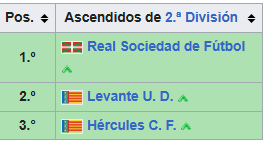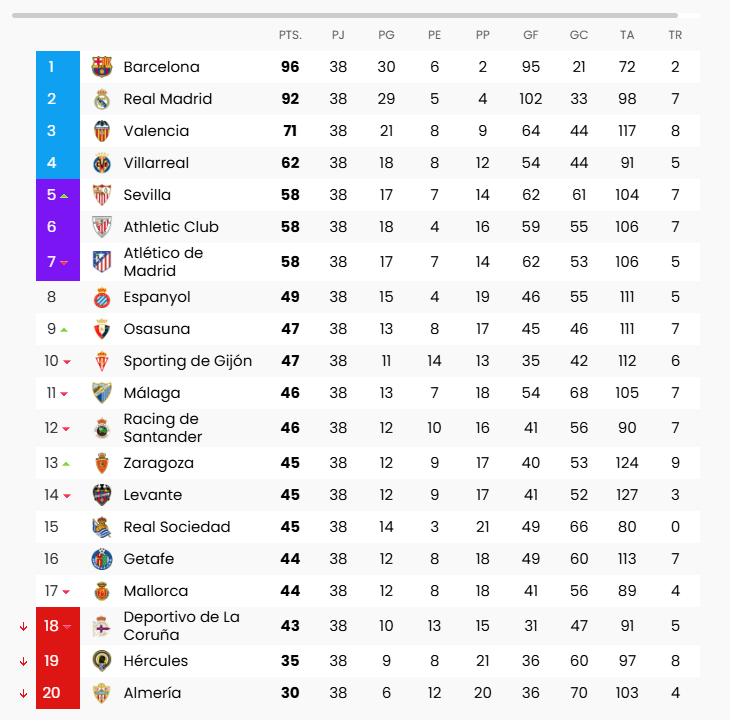 https://www.bdfutbol.com/es/t/t2010-11.html esto es para saber quiénes son los ascendidos en nuestra primera temporada

### Creación de variables

### Análisis exploratorio de las variables creadas

### Partidos sin historial

### División del dataset

### Normalizar los valores de los vectores